# Part 1: a modest improvement on both required CV pools

The selected model scores **0.925265 versus current Ani's 0.921444** on the 157-label CV and **0.921543 versus 0.913741** on the 235-label CV. Mean macro F1 improves in both pools. All four additional validation/chronological sample-F1 checks improve against the same current Ani source.

This is a local development improvement, **not a demonstrated Kaggle win or the requested 0.05 leaderboard gain**. Training-pool evidence remains noisy: its descriptive paired interval includes zero. All folds and diagnostics have been used repeatedly for development; selection can overfit them.

## Exact comparison

- Comparator: Ani commit `8a8c3fca70f13b62e989739a0bc1d97d229186e1`, archived in `experiments/current_ani_pool_audit/ani_current_source.ipynb`. This is the current recipe with LDA and C=0.1, not the older no-LDA reference.
- **157 known training labels:** five saved repeats of three-fold CV, seeds42–46, 103–106 fitting labels per fold. All78 validation inputs and labels are excluded from these fits.
- **235 known train+validation labels:** eight saved repeats of five-fold CV, seeds100–107, 188 fitting labels per fold.
- Both use the same1,014 originally unlabeled training rows. Every scaler, PCA, GMM and augmented classifier is fitted inside each fold. Held-out and Kaggle test inputs are excluded from all fitting and pseudo-labeling. No new folds were generated.
- Sample F1 is computed across the pooled out-of-fold rows within each repeat, then averaged across repeats. Unequal-sized157-pool folds are not averaged with equal weights.
- The native Ani notebook uses broader feature access. This comparison applies the repository's active strict fold-local feature policy to both recipes.

The new runner reproduces Ani's labels on all55 folds with maximum score difference1.1e-16. The previous trusted candidate's labels also reproduce on all55 folds (maximum score difference1.7e-9). Two aborted roundoff-control attempts, before interpreting results, are retained in the `00_...` folders.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display
PART1=Path.cwd()
if not (PART1/'data/part1_train.csv').exists():PART1=PART1/'part1'
OUT=PART1/'experiments/paired_improvement'
comparison=pd.read_csv(OUT/'selected_comparison.csv')
display(comparison[['pool','name','mean_f1','repeat_sd','macro_f1','delta_ani','repeat_wins','repeat_ties','fold_wins','fold_ties']].round(6))
display(comparison[['pool','name','f1_Safety','f1_Funding','f1_Efficacy','f1_Recruitment','f1_Other']].round(6))


,pool,name,mean_f1,repeat_sd,macro_f1,delta_ani,repeat_wins,repeat_ties,fold_wins,fold_ties
0,train157,ani_current,0.921444,0.007355,0.872553,0.000000,0.0,5.0,0.0,15.0
1,train157,selected_control,0.925265,0.007262,0.874925,0.003822,3.0,1.0,8.0,1.0
2,train157,trusted_two_pass,0.920594,0.008439,0.856218,-0.000849,1.0,2.0,5.0,5.0
3,trainval235,ani_current,0.913741,0.006297,0.836665,0.000000,0.0,8.0,0.0,40.0
4,trainval235,selected_control,0.921543,0.003883,0.848384,0.007801,6.0,0.0,26.0,6.0
5,trainval235,trusted_two_pass,0.915337,0.004152,0.831522,0.001596,5.0,0.0,20.0,7.0


,pool,name,f1_Safety,f1_Funding,f1_Efficacy,f1_Recruitment,f1_Other
0,train157,ani_current,0.897386,0.906092,0.924307,0.956948,0.678030
1,train157,selected_control,0.920536,0.906092,0.908167,0.967112,0.672716
2,train157,trusted_two_pass,0.930905,0.829359,0.892661,0.967993,0.660173
3,trainval235,ani_current,0.913298,0.817210,0.872468,0.973269,0.607079
4,trainval235,selected_control,0.935663,0.832246,0.872379,0.978321,0.623310
5,trainval235,trusted_two_pass,0.920669,0.773221,0.867622,0.977536,0.618564


The candidate wins3 of5 training-pool repeat averages, ties1 and loses1; its fold record is8 wins/1 tie/6 losses. It wins6 of8 full-pool repeat averages; its fold record is26 wins/6 ties/8 losses. The direction is favorable on average, not on every split.

Funding is unchanged on157 and improves on235. Efficacy falls on157 and is essentially unchanged on235. Safety and Recruitment improve in both pools; Other improves on235 but falls slightly on157. This is not a uniform gain across all reasons.


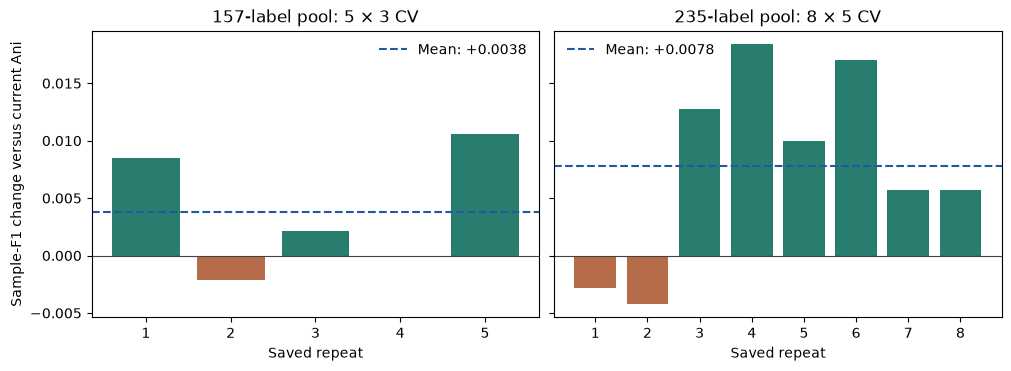

,pool,delta,lower_95,upper_95,caveat
0,train157,0.003822,-0.005955,0.013588,Descriptive paired-trial bootstrap. Not adjust...
1,trainval235,0.007801,0.002837,0.013475,Descriptive paired-trial bootstrap. Not adjust...


In [2]:
import matplotlib.pyplot as plt
repeat=pd.read_csv(OUT/'06_final_ablations/repeat_scores.csv')
fig,axes=plt.subplots(1,2,figsize=(10,3.6),sharey=True,constrained_layout=True)
for ax,pool,title in zip(axes,['train157','trainval235'],['157-label pool: 5 × 3 CV','235-label pool: 8 × 5 CV']):
    w=repeat[repeat.pool==pool].pivot(index='repeat',columns='name',values='sample_f1')
    delta=w.selected_control-w.ani_current
    ax.bar(np.arange(len(delta))+1,delta,color=['#287d6e' if v>0 else '#b66c48' for v in delta])
    ax.axhline(0,color='#444444',linewidth=.8)
    ax.axhline(delta.mean(),color='#2159a0',linestyle='--',label=f'Mean: {delta.mean():+.4f}')
    ax.set(title=title,xlabel='Saved repeat',xticks=np.arange(len(delta))+1)
    ax.legend(frameon=False)
axes[0].set_ylabel('Sample-F1 change versus current Ani')
fig.savefig(OUT/'paired_repeat_changes.pdf')
fig.savefig(OUT/'paired_repeat_changes.png',dpi=160)
plt.show()
display(pd.read_csv(OUT/'paired_trial_bootstrap.csv').round(6))


The interval above resamples trials after averaging each trial's paired difference across repeats. It is descriptive; it does not account for choosing the recipe on these same data, overlapping training folds, or the many earlier searches. Do not interpret the positive235-pool interval as a confirmatory significance test.

## Four additional checks

The original split fits157 labels and holds out78. The chronological checks fit only trials starting no later than2003,2005 or2007 and evaluate later trials. Unlabeled trials after the cutoff are excluded too. These checks are reused development diagnostics. Compared with the previous trusted candidate, the new model improves the original split and2005 check, but is lower on2003 and2007; against current Ani, it improves all four.


In [3]:
diagnostics=pd.read_csv(OUT/'selected_diagnostics.csv')
display(diagnostics[['split','name','fit_rows','unlabeled_rows','held_rows','sample_f1','macro_f1']].round(6))


,split,name,fit_rows,unlabeled_rows,held_rows,sample_f1,macro_f1
0,original_validation,ani_current,157,1014,78,0.871795,0.742026
1,original_validation,trusted_two_pass,157,1014,78,0.880342,0.695565
2,after_2003,ani_current,126,60,109,0.811927,0.759425
3,after_2003,trusted_two_pass,126,60,109,0.824159,0.778561
4,after_2005,ani_current,149,302,86,0.860465,0.820562
5,after_2005,trusted_two_pass,149,302,86,0.860465,0.804538
6,after_2007,ani_current,198,724,37,0.864865,0.828648
7,after_2007,trusted_two_pass,198,724,37,0.887387,0.848936
8,original_validation,selected_control,157,1014,78,0.891026,0.765430
9,after_2003,selected_control,126,60,109,0.822630,0.769874


## What changed and why

The PDF says embeddings come from the actual stopping-reason text, were reduced with PCA and randomly rotated, and should be standardized. They are direct evidence of the target. The model uses all150 embeddings and no trial identifiers, drug features, disease labels or eligibility text. PCA30 and a diagonal30-component GMM remain the unsupervised component assisting automatic label generation; classifiers retain all150 dimensions.

Keep Ani's logistic C=0.1, final mixture0.5 logistic/0.3 cosine neighbors/0.2 shrinkage LDA, ten neighbors, two pseudo-labeling passes, acceptance confidence0.8, and final cutoff0.3 with argmax fallback. Change only:

1. Compute logistic class weights once from verified labels. Generated labels cannot change the class balance.
2. Give generated rows one-quarter weight in logistic regression. LDA and neighbors retain their original unweighted fitting; quarter weighting does not apply to them.
3. Let a neighbor with two reasons vote fully for both rather than splitting its vote.
4. Reduce GMM assistance during pseudo-label selection from20% to5%. The final prediction still uses only the supervised mixture.

The compact implementation is `anchored_solution.py`. It contains no additional model stack or learned second-stage combiner. The full-data fit uses235 known rows, accepts685 generated rows after the first pass and757 after the second. Verified labels are never overwritten.

## Methodical experiment record

Each fitted recipe was evaluated on both saved pools and all four diagnostics. There are36 named fitted evaluations representing31 distinct recipes, including controls, plus two new final-cutoff alternatives reusing the same55 fold score arrays. Every negative result is retained.

1. Add LDA to the simpler trusted recipe; compare fitting LDA on verified versus augmented labels. Augmented LDA helps more on235; restricting it to verified rows does not improve both pools.
2. Check generated-row weight, LDA weight, confidence and number of passes. A small amount of GMM assistance is more balanced than eliminating it.
3. Reduce either all classifier inputs or just LDA inputs to30/60 PCs. These changes hurt the two-pool comparison, despite a strong original-validation score for one variant; reject them.
4. Check5/20 neighbors and GMM weight0.05/0.15 around the0.1 candidate. Retain ten neighbors and0.05 GMM weight.
5. Check final decision cutoff0.25/0.35. Retain0.3.
6. Check logistic C=0.05/0.2 and revert each proposed change individually. Retain C=0.1. Reverting anchored class balance loses the157-pool gain; full generated-row weight also hurts157. Fractional neighbor votes lower both means. Restoring GMM0.2 improves157 but loses most of the235 gain.

Selection favored improving both pools, with the minimum of the two mean gains used for comparison. That is a development selection rule, not an independent test.


In [4]:
all_results=pd.read_csv(OUT/'all_results.csv')
display(all_results[['stage','pool','name','mean_f1','macro_f1','delta_ani']].round(6))
display(pd.read_csv(OUT/'06_final_ablations/both_pools.csv').round(6))


,stage,pool,name,mean_f1,macro_f1,delta_ani
0,01_rare_reason_structure,train157,ani_current,0.921444,0.872553,0.000000
1,01_rare_reason_structure,train157,ani_exact_control,0.921444,0.872553,0.000000
2,01_rare_reason_structure,train157,ani_trust_and_binary,0.926539,0.877473,0.005096
3,01_rare_reason_structure,train157,ani_without_gmm,0.919745,0.870971,-0.001699
4,01_rare_reason_structure,train157,trusted_exact_control,0.920594,0.856218,-0.000849
...,...,...,...,...,...,...
97,06_final_ablations,trainval235,ani_current,0.913741,0.836665,0.000000
98,06_final_ablations,trainval235,regularization_C0.05,0.922784,0.848204,0.009043
99,06_final_ablations,trainval235,regularization_C0.2,0.920656,0.846307,0.006915
100,06_final_ablations,trainval235,selected_control,0.921543,0.848384,0.007801


,name,mean_f1_train157,mean_f1_trainval235,delta_ani_train157,delta_ani_trainval235,macro_f1_train157,macro_f1_trainval235,minimum_delta
0,selected_control,0.925265,0.921543,0.003822,0.007801,0.874925,0.848384,0.003822
1,ablation_fractional_neighbors,0.923567,0.920124,0.002123,0.006383,0.873267,0.848269,0.002123
2,regularization_C0.05,0.922718,0.922784,0.001274,0.009043,0.870293,0.848204,0.001274
3,ablation_original_gmm,0.926539,0.914982,0.005096,0.001241,0.877473,0.837745,0.001241
4,ani_current,0.921444,0.913741,0.000000,0.000000,0.872553,0.836665,0.000000
5,ablation_augmented_balance,0.921019,0.917465,-0.000425,0.003723,0.873470,0.844965,-0.000425
6,trusted_two_pass,0.920594,0.915337,-0.000849,0.001596,0.856218,0.831522,-0.000849
7,regularization_C0.2,0.920170,0.920656,-0.001274,0.006915,0.865936,0.846307,-0.001274
8,ablation_full_pseudo_weight,0.919321,0.923316,-0.002123,0.009574,0.861851,0.849963,-0.002123


## Independent replay and saved candidate

The compact implementation was fitted independently on all55 saved folds and all four diagnostic splits. Every predicted label matches the selected experiment; the maximum fold-score difference is below2.1e-10. All pooled metrics were recalculated. Original labels, old candidate artifacts and protected benchmark files passed checksum checks. The serialized model reproduces its predictions exactly after reload.

`experiments/paired_improvement/candidate/part1_anchored_submission.csv` contains312 checked rows in sample-submission order and has **not been uploaded**. Its manifest records source/data/artifact hashes, versions, fitting counts and the exact selected recipe. The folder also includes generated-label decisions, the augmented training CSV, prediction scores and the model. All known labels remain intact.


In [5]:
manifest=json.loads((OUT/'candidate/manifest.json').read_text())
checks=json.loads((OUT/'candidate/independent_replay_checks.json').read_text())
assert len(checks['cv'])==55 and len(checks['diagnostics'])==4
for row in checks['cv']:
    assert set(row['feature_ids']).isdisjoint(row['held_ids'])
    assert len(row['unknown_ids'])==1014 and not row['test_features_used']
display({k:manifest[k] for k in ['status','known_labels','originally_unlabeled','test_rows','final_fit_audit','independent_fold_replays','independent_diagnostic_replays','protected_originals_unchanged','kaggle_score','versions']})
print('Maximum independent replay score error:',max(r['max_score_error'] for r in checks['cv']))


{'status': 'Unsubmitted candidate; local CV improvement over pinned current Ani, Kaggle performance unknown.',
 'known_labels': 235,
 'originally_unlabeled': 1014,
 'test_rows': 312,
 'final_fit_audit': [{'step': 0,
   'known': 235,
   'generated': 0,
   'known_weight': 235.0,
   'generated_weight': 0.0},
  {'step': 1,
   'known': 235,
   'generated': 685,
   'known_weight': 235.0,
   'generated_weight': 102.79687754649603},
  {'step': 2,
   'known': 235,
   'generated': 757,
   'known_weight': 235.0,
   'generated_weight': 119.52692709831274}],
 'independent_fold_replays': 55,
 'independent_diagnostic_replays': 4,
 'protected_originals_unchanged': True,
 'kaggle_score': None,
 'versions': {'python': '3.12.13',
  'sklearn': '1.9.0',
  'numpy': '2.5.2',
  'pandas': '3.0.5',
  'joblib': '1.6.0'}}

Maximum independent replay score error: 2.075286609226623e-10


## Reproducible source

The following cells contain the complete code used by this study, including the small unchanged shared helpers it calls. Frozen per-stage copies are also saved beside each protocol. The current-Ani reference's original notebook and its55-fold audit are archived separately, with exact commit provenance and split hashes.

From the repository root, `.venv/bin/python part1/paired_finalize.py` reruns the55-fold/four-diagnostic independent replay and local export. It does not submit to Kaggle. For an individual original experiment use `PYTHONPATH=part1 .venv/bin/python part1/experiments/paired_improvement/STAGE/paired_search.py --stage STAGE --specs SPEC_FILE --diagnostics`, using that stage's protocol specs. The frozen scripts use their adjacent model source. Current runner source intentionally rejects overwriting an existing stage with changed source.

The notebook defaults to reading saved evidence. Optional replay cells below write new experiment folders; the checked reference and old candidates stay intact.


In [6]:
import sys,types
from IPython.core.magic import register_cell_magic
sys.path.insert(0,str(PART1))
@register_cell_magic
def source_module(name,source):
    module=types.ModuleType(name.strip());module.__file__=str(PART1/(name.strip()+'.py'))
    sys.modules[name.strip()]=module
    exec(compile(source,module.__file__,'exec'),module.__dict__)


In [7]:
%%source_module simple_models
import numpy as np
REASONS = ['Safety', 'Funding', 'Efficacy', 'Recruitment', 'Other']

FEATURES = [f'emb_{i}' for i in range(150)]

def decide(probability, cutoff=.5):
    prediction = (probability >= cutoff).astype(int)
    empty = np.flatnonzero(prediction.sum(axis=1) == 0)
    prediction[empty, probability[empty].argmax(axis=1)] = 1
    return prediction

In [8]:
%%source_module simple_benchmark
import hashlib
from pathlib import Path
from sklearn.metrics import f1_score
from simple_models import REASONS
ROOT = Path(__file__).resolve().parent

BASE = ROOT / 'experiments/paired_recipe_cv'

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def metrics(Y, prediction):
    return dict(sample_f1=float(f1_score(Y, prediction, average='samples', zero_division=0)),
                macro_f1=float(f1_score(Y, prediction, average='macro', zero_division=0)),
                **dict(zip([f'f1_{r}' for r in REASONS], f1_score(Y, prediction, average=None, zero_division=0))))

In [9]:
%%source_module paired_models
"""Small controlled changes to current Ani and the trusted two-pass recipe."""
import numpy as np
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler, normalize

from simple_models import decide

ANI = dict(C=.1, pseudo_weight=1., balance_source='augmented', binary_neighbors=False,
           lda_weight=.2, lda_source='augmented', gmm_weight=.2, rounds=2)
TRUSTED = dict(C=.3, pseudo_weight=.25, balance_source='verified', binary_neighbors=True,
               lda_weight=0., gmm_weight=0., rounds=2)


def prepare(features, use_gmm=True):
    """Only features explicitly permitted by the outer/inner fitting split enter."""
    scaler=StandardScaler().fit(features)
    prep=dict(scaler=scaler)
    if use_gmm:
        Z=scaler.transform(features)
        pca=PCA(30,random_state=0).fit(Z)
        gmm=GaussianMixture(30,covariance_type='diag',n_init=3,random_state=0).fit(pca.transform(Z))
        assert gmm.converged_
        prep.update(pca=pca,gmm=gmm)
    return prep


def expand(Y):
    row, reason=np.nonzero(Y)
    weight=1./Y.sum(axis=1)[row]
    return row,reason,weight


def lda_fit(Z,Y):
    row,reason,_=expand(Y)
    k=len(np.unique(reason))
    return LinearDiscriminantAnalysis(solver='lsqr',shrinkage='auto',priors=np.ones(k)/k).fit(Z[row],reason)


class PairedModel:
    def __init__(self,spec):
        self.spec=dict(spec)

    def fit(self,X,Y,U,preprocessor=None):
        s=self.spec
        # Preserve each reference's scaler summation order exactly. Both contain
        # the same permitted rows; the GMM reference uses original CSV order.
        self.preprocessor_=(preprocessor or prepare(np.vstack([X,U]),True)) if s.get('gmm_weight',0)>0 else prepare(np.vstack([X,U]),False)
        self.scaler_=self.preprocessor_['scaler']
        Z,V=self.scaler_.transform(X),self.scaler_.transform(U)
        row,reason,weights=expand(Y)
        verified_counts=(Y/Y.sum(axis=1,keepdims=True)).sum(axis=0)
        if s.get('gmm_weight',0):
            pca,gmm=self.preprocessor_['pca'],self.preprocessor_['gmm']
            Rk=gmm.predict_proba(pca.transform(Z));Ru=gmm.predict_proba(pca.transform(V))
            Ra=Rk
        self.base_projection_=None
        if s.get('base_components'):
            self.base_projection_=PCA(s['base_components'],random_state=0).fit(np.vstack([Z,V]))
            Z,V=self.base_projection_.transform(Z),self.base_projection_.transform(V)
        self.lda_projection_=None
        if s.get('lda_components'):
            self.lda_projection_=PCA(s['lda_components'],random_state=0).fit(np.vstack([Z,V]))
        self.known_lda_=lda_fit(self._lda_features(Z),Y) if s.get('lda_weight',0)>0 and s.get('lda_source')=='verified' else None
        Za,Ya=Z,Y
        self.audit_=[]
        self.generated_mask_=np.zeros(len(U),bool)
        self.generated_labels_=np.empty((0,5),int)
        for step in range(s.get('rounds',2)+1):
            row,reason,weights=expand(Ya)
            counts=(np.bincount(reason,weights=weights,minlength=5)+1e-9) if s.get('balance_source','augmented')=='augmented' else verified_counts
            weights=weights*counts.mean()/counts[reason] if s.get('balance_source','augmented')=='augmented' else (counts.mean()/counts[reason])/Ya.sum(axis=1)[row]
            weights*=np.where(row<len(X),1.,s.get('pseudo_weight',1.))
            self.lr_=LogisticRegression(C=s.get('C',.1),max_iter=3000,tol=s.get('tol',1e-4)).fit(Za[row],reason,sample_weight=weights)
            self.lda_=None
            if s.get('lda_weight',0)>0:
                self.lda_=self.known_lda_ if self.known_lda_ is not None else lda_fit(self._lda_features(Za),Ya)
            self.neighbor_X_=normalize(Za)
            self.neighbor_Y_=Ya.copy() if s.get('binary_neighbors',False) else Ya/Ya.sum(axis=1,keepdims=True)
            self.audit_.append(dict(step=step,known=len(X),generated=len(Za)-len(X),known_weight=float(weights[row<len(X)].sum()),generated_weight=float(weights[row>=len(X)].sum())))
            if step==s.get('rounds',2):break
            P=self._base(V)
            if s.get('gmm_weight',0):
                T=Ya/Ya.sum(axis=1,keepdims=True)
                rates=(Ra.T@T+T.mean(axis=0))/(Ra.sum(axis=0)[:,None]+1)
                P=(1-s['gmm_weight'])*P+s['gmm_weight']*(Ru@rates)
            keep=P.max(axis=1)>=s.get('confidence',.8)
            self.generated_mask_=keep
            self.generated_labels_=decide(P[keep],.3)
            Za=np.vstack([Z,V[keep]]);Ya=np.vstack([Y,self.generated_labels_])
            if s.get('gmm_weight',0):Ra=np.vstack([Rk,Ru[keep]])
        return self

    def _base(self,Z):
        lr=np.zeros((len(Z),5));lr[:,self.lr_.classes_]=self.lr_.predict_proba(Z)
        similarity=normalize(Z)@self.neighbor_X_.T
        neighbors=np.argsort(-similarity,axis=1)[:,:self.spec.get('k',10)]
        weight=np.take_along_axis(similarity,neighbors,axis=1).clip(0)**2
        local=(weight[:,:,None]*self.neighbor_Y_[neighbors]).sum(axis=1)/(weight.sum(axis=1,keepdims=True)+1e-9)
        wknn=self.spec.get('knn_weight',.3);wlda=self.spec.get('lda_weight',0.)
        P=(1-wknn-wlda)*lr+wknn*local
        if self.lda_ is not None:
            ld=np.zeros_like(P);ld[:,self.lda_.classes_]=self.lda_.predict_proba(self._lda_features(Z))
            P+=wlda*ld
        return P

    def _lda_features(self,Z):
        return self.lda_projection_.transform(Z) if self.lda_projection_ is not None else Z

    def predict_proba(self,X):
        Z=self.scaler_.transform(X)
        if self.base_projection_ is not None:Z=self.base_projection_.transform(Z)
        return self._base(Z)
    def predict(self,X):return decide(self.predict_proba(X),self.spec.get('cutoff',.3))


def first_specs():
    return [dict(ANI,name='ani_exact_control'),dict(TRUSTED,name='trusted_exact_control'),
            dict(TRUSTED,name='trusted_lda_verified',lda_weight=.2,lda_source='verified'),
            dict(TRUSTED,name='trusted_lda_augmented',lda_weight=.2,lda_source='augmented'),
            dict(TRUSTED,name='trusted_lda_verified_C0.1',lda_weight=.2,lda_source='verified',C=.1),
            dict(TRUSTED,name='trusted_lda_augmented_C0.1',lda_weight=.2,lda_source='augmented',C=.1),
            dict(TRUSTED,name='trusted_lda_verified_w0.1',lda_weight=.1,lda_source='verified'),
            dict(ANI,name='ani_without_gmm',gmm_weight=0.),
            dict(ANI,name='ani_trust_and_binary',pseudo_weight=.25,balance_source='verified',binary_neighbors=True)]


In [10]:
%%source_module paired_search
"""Run every new candidate on both saved label pools, against pinned current Ani."""
import argparse
import json
from pathlib import Path
import shutil
import time
import warnings

import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

from simple_benchmark import ROOT,BASE,digest,metrics
from simple_models import FEATURES,REASONS,decide
from paired_models import PairedModel,prepare,first_specs

OUT=ROOT/'experiments/paired_improvement'
REFERENCE=ROOT/'experiments/current_ani_pool_audit'


def pools():
    train=pd.read_csv(ROOT/'data/part1_train.csv');valid=pd.read_csv(ROOT/'data/part1_val.csv')
    unknown=np.flatnonzero(train[REASONS].lt(0).all(axis=1).to_numpy())
    return [('train157',train,ROOT/'experiments/classifier_cross_validation/splits',5,3,unknown),
            ('trainval235',pd.concat([train,valid],ignore_index=True),BASE/'splits',8,5,unknown)]


def summarize(stage,df):
    reasons=REASONS
    fold_rows=[];repeat_rows=[]
    for (pool,name,repeat,fold),g in df.groupby(['pool','name','repeat','fold'],sort=True):
        fold_rows.append(dict(pool=pool,name=name,repeat=repeat,fold=fold,**metrics(g[[f'actual_{r}' for r in reasons]].to_numpy(),g[[f'predicted_{r}' for r in reasons]].to_numpy())))
    for (pool,name,repeat),g in df.groupby(['pool','name','repeat'],sort=True):
        assert len(g)==g.ID.nunique()==(157 if pool=='train157' else 235)
        repeat_rows.append(dict(pool=pool,name=name,repeat=repeat,**metrics(g[[f'actual_{r}' for r in reasons]].to_numpy(),g[[f'predicted_{r}' for r in reasons]].to_numpy())))
    folds=pd.DataFrame(fold_rows);repeats=pd.DataFrame(repeat_rows)
    summary=repeats.groupby(['pool','name']).agg(mean_f1=('sample_f1','mean'),repeat_sd=('sample_f1','std'),macro_f1=('macro_f1','mean'),**{f'f1_{r}':(f'f1_{r}','mean') for r in reasons})
    for pool in ['train157','trainval235']:
        ref=repeats[(repeats.pool==pool)&(repeats.name=='ani_current')].sample_f1.to_numpy()
        ref_fold=folds[(folds.pool==pool)&(folds.name=='ani_current')].sample_f1.to_numpy()
        for name in summary.loc[pool].index:
            diff=repeats[(repeats.pool==pool)&(repeats.name==name)].sample_f1.to_numpy()-ref
            fd=folds[(folds.pool==pool)&(folds.name==name)].sample_f1.to_numpy()-ref_fold
            summary.loc[(pool,name),'delta_ani']=diff.mean()
            summary.loc[(pool,name),'repeat_wins']=sum(diff>1e-12);summary.loc[(pool,name),'repeat_ties']=sum(abs(diff)<1e-12)
            summary.loc[(pool,name),'fold_wins']=sum(fd>1e-12);summary.loc[(pool,name),'fold_ties']=sum(abs(fd)<1e-12)
    summary.to_csv(stage/'summary.csv');repeats.to_csv(stage/'repeat_scores.csv',index=False);folds.to_csv(stage/'fold_scores.csv',index=False)
    combined=summary.reset_index().pivot(index='name',columns='pool',values=['mean_f1','delta_ani','macro_f1'])
    combined.columns=['_'.join(c) for c in combined.columns]
    combined['minimum_delta']=combined[['delta_ani_train157','delta_ani_trainval235']].min(axis=1)
    combined.sort_values('minimum_delta',ascending=False).to_csv(stage/'both_pools.csv')
    print(combined.sort_values('minimum_delta',ascending=False).to_string(),flush=True)
    return summary


def run(stage_name,specs):
    stage=OUT/stage_name;stage.mkdir(parents=True,exist_ok=True)
    baseline_protocol=json.loads((REFERENCE/'protocol.json').read_text())
    baseline=pd.read_csv(REFERENCE/'predictions.csv')
    baseline=baseline[baseline.name.isin(['ani_current','trusted_two_pass'])].copy()
    protocol=dict(stage=stage_name,specs=specs,ani_commit=baseline_protocol['ani_commit'],pools=baseline_protocol['pools'],
                  features='150 supplied reason embeddings only',feature_policy=baseline_protocol['policy'],
                  selection='Prefer improvements on both pools; neither may be silently dropped. No test labels or inputs in fitting.',
                  reference_sha256=digest(REFERENCE/'predictions.csv'),input_sha256={p.name:digest(p) for p in [ROOT/'data/part1_train.csv',ROOT/'data/part1_val.csv']})
    if (stage/'protocol.json').exists():assert json.loads((stage/'protocol.json').read_text())==protocol
    else:(stage/'protocol.json').write_text(json.dumps(protocol,indent=2)+'\n')
    for filename in ['paired_models.py','paired_search.py']:
        source=Path(__file__).resolve().parent/filename
        if (stage/filename).exists():
            assert digest(source)==digest(stage/filename), f'Source changed: use a new stage or execute its frozen sources: {filename}'
        else:shutil.copyfile(source,stage/filename)
    outputs=[];audits=[];controls=[];start=time.time()
    with threadpool_limits(limits=1),warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        for pool,frame,splitdir,nrep,nfold,unknown in pools():
            verified=np.flatnonzero(frame[REASONS].ge(0).all(axis=1).to_numpy())
            X=frame[FEATURES].to_numpy();Y=frame[REASONS].to_numpy(int)
            for repeat in range(nrep):
                assignment=pd.read_csv(splitdir/f'repeat{repeat}.csv').set_index('ID').loc[frame.iloc[verified].ID,'fold'].to_numpy()
                assert digest(splitdir/f'repeat{repeat}.csv')==protocol['pools'][pool]['split_sha256'][f'repeat{repeat}.csv']
                for fold in range(nfold):
                    fit=verified[assignment!=fold];held=verified[assignment==fold];feature_rows=np.sort(np.r_[fit,unknown])
                    assert not np.intersect1d(feature_rows,held).size
                    prep=prepare(X[feature_rows],any(s.get('gmm_weight',0)>0 for s in specs))
                    for s in specs:
                        model=PairedModel(s).fit(X[fit],Y[fit],X[unknown],prep)
                        P=model.predict_proba(X[held]);pred=decide(P,s.get('cutoff',.3))
                        assert np.isfinite(P).all() and pred.sum(axis=1).min()>0
                        if s['name'] in ['ani_exact_control','trusted_exact_control']:
                            name='ani_current' if s['name']=='ani_exact_control' else 'trusted_two_pass'
                            old=baseline[(baseline.pool==pool)&(baseline.repeat==repeat)&(baseline.fold==fold)&(baseline.name==name)].set_index('ID').loc[frame.iloc[held].ID]
                            old_p=old[[f'probability_{r}' for r in REASONS]].to_numpy()
                            # Equivalent floating-point operation/scaler row order can
                            # perturb optimizer convergence. Require identical labels,
                            # and record the maximum score error, bounded to 1e-6.
                            np.testing.assert_allclose(P,old_p,atol=1e-6,rtol=0,err_msg=f'{pool}/{repeat}/{fold}/{name}')
                            np.testing.assert_array_equal(pred,old[[f'predicted_{r}' for r in REASONS]])
                            controls.append(dict(pool=pool,repeat=repeat,fold=fold,name=name,max_abs_score_error=float(abs(P-old_p).max()),identical_predictions=True))
                        out=pd.DataFrame(dict(ID=frame.iloc[held].ID,pool=pool,name=s['name'],repeat=repeat,fold=fold))
                        for j,r in enumerate(REASONS):out[f'actual_{r}']=Y[held,j];out[f'predicted_{r}']=pred[:,j];out[f'probability_{r}']=P[:,j]
                        outputs.append(out)
                        audits.append(dict(pool=pool,repeat=repeat,fold=fold,name=s['name'],fit_ids=frame.iloc[fit].ID.tolist(),held_ids=frame.iloc[held].ID.tolist(),unlabeled_count=len(unknown),feature_count=len(feature_rows),fit_audit=model.audit_))
                print(stage_name,pool,f'repeat {repeat+1}/{nrep}',round(time.time()-start,1),'s',flush=True)
    df=pd.concat([baseline,*outputs],ignore_index=True)
    df.to_csv(stage/'predictions.csv',index=False)
    (stage/'fit_audits.json').write_text(json.dumps(audits,separators=(',',':'))+'\n')
    (stage/'control_checks.json').write_text(json.dumps(controls,indent=2)+'\n')
    summarize(stage,pd.read_csv(stage/'predictions.csv'))
    return stage


def diagnostics(stage_name):
    stage=OUT/stage_name;specs=json.loads((stage/'protocol.json').read_text())['specs']
    _,frame,_,_,_,unknown=pools()[1]
    verified=np.flatnonzero(frame[REASONS].ge(0).all(axis=1).to_numpy());X=frame[FEATURES].to_numpy();Y=frame[REASONS].to_numpy(int)
    rows=[];outputs=[]
    with threadpool_limits(limits=1),warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        for label in ['original_validation','after_2003','after_2005','after_2007']:
            if label=='original_validation':fit=verified[:157];held=verified[157:];u=unknown
            else:
                year=int(label.split('_')[-1]);early=frame.start_year.to_numpy()<=year
                fit=verified[early[verified]];held=verified[~early[verified]];u=unknown[early[unknown]]
            prep=prepare(X[np.sort(np.r_[fit,u])],any(s.get('gmm_weight',0)>0 for s in specs))
            for s in specs:
                model=PairedModel(s).fit(X[fit],Y[fit],X[u],prep);P=model.predict_proba(X[held]);pred=decide(P,s.get('cutoff',.3))
                rows.append(dict(split=label,name=s['name'],fit_rows=len(fit),held_rows=len(held),unlabeled_rows=len(u),**metrics(Y[held],pred)))
                out=pd.DataFrame(dict(ID=frame.iloc[held].ID,split=label,name=s['name']))
                for j,r in enumerate(REASONS):out[f'actual_{r}']=Y[held,j];out[f'predicted_{r}']=pred[:,j];out[f'probability_{r}']=P[:,j]
                outputs.append(out)
            print(label,{r['name']:round(r['sample_f1'],6) for r in rows if r['split']==label},flush=True)
    ref=pd.read_csv(REFERENCE/'current_diagnostic_scores.csv');ref=ref[ref.name.isin(['ani_current','trusted_two_pass'])]
    pd.concat([ref,pd.DataFrame(rows)]).to_csv(stage/'diagnostic_scores.csv',index=False)
    pd.concat(outputs).to_csv(stage/'diagnostic_predictions.csv',index=False)


if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('--stage',required=True);p.add_argument('--specs',type=Path);p.add_argument('--diagnostics',action='store_true')
    a=p.parse_args();run(a.stage,json.loads(a.specs.read_text()) if a.specs else first_specs())
    if a.diagnostics:diagnostics(a.stage)


In [11]:
%%source_module paired_cutoffs
"""Two fixed final-decision sensitivity checks; reuse all 55 fitted fold scores."""
import argparse
import json
from pathlib import Path

import pandas as pd

from simple_benchmark import digest,metrics
from simple_models import REASONS,decide
from paired_search import OUT,REFERENCE,summarize


def run(source_stage,source_name):
    parent=OUT/source_stage
    stage=OUT/'05_final_decision';stage.mkdir(exist_ok=True)
    protocol=dict(parent=source_stage,name=source_name,cutoffs=[.25,.3,.35],
                  parent_sha256={f:digest(parent/f) for f in ['protocol.json','predictions.csv','diagnostic_predictions.csv']},
                  policy='Only the final prediction cutoff changes. Fitting and pseudo-label cutoff stay fixed; reuse every saved fold score in both pools. These are development comparisons.')
    (stage/'protocol.json').write_text(json.dumps(protocol,indent=2)+'\n')
    (stage/'paired_cutoffs.py').write_bytes(Path(__file__).read_bytes())
    source=pd.read_csv(parent/'predictions.csv');source=source[source.name==source_name]
    baseline=pd.read_csv(REFERENCE/'predictions.csv');baseline=baseline[baseline.name.isin(['ani_current','trusted_two_pass'])]
    outputs=[];diagnostic_outputs=[];rows=[]
    diagnostics=pd.read_csv(parent/'diagnostic_predictions.csv');diagnostics=diagnostics[diagnostics.name==source_name]
    for cutoff in protocol['cutoffs']:
        for original,result in [(source,outputs),(diagnostics,diagnostic_outputs)]:
            df=original.copy();df['name']=f'cutoff_{cutoff}'
            pred=decide(df[[f'probability_{r}' for r in REASONS]].to_numpy(),cutoff)
            for j,r in enumerate(REASONS):df[f'predicted_{r}']=pred[:,j]
            result.append(df)
    df=pd.concat([baseline,*outputs],ignore_index=True);df.to_csv(stage/'predictions.csv',index=False)
    summarize(stage,df)
    dp=pd.concat(diagnostic_outputs,ignore_index=True);dp.to_csv(stage/'diagnostic_predictions.csv',index=False)
    for (split,name),g in dp.groupby(['split','name']):
        rows.append(dict(split=split,name=name,**metrics(g[[f'actual_{r}' for r in REASONS]].to_numpy(),g[[f'predicted_{r}' for r in REASONS]].to_numpy())))
    ref=pd.read_csv(REFERENCE/'current_diagnostic_scores.csv');ref=ref[ref.name.isin(['ani_current','trusted_two_pass'])]
    pd.concat([ref,pd.DataFrame(rows)]).to_csv(stage/'diagnostic_scores.csv',index=False)
    print(pd.DataFrame(rows).pivot(index='name',columns='split',values='sample_f1').to_string())


if __name__=='__main__':
    p=argparse.ArgumentParser();p.add_argument('stage');p.add_argument('name');a=p.parse_args();run(a.stage,a.name)


In [12]:
%%source_module anchored_solution
"""Current Ani with three small changes: anchored weights, binary votes, weaker GMM.

Fit receives only permitted rows, in original CSV order. Fully missing labels
are -100; query/test rows must never be passed to fit. Prediction uses only the
150 stopping-reason embedding columns, ordered emb_0 through emb_149.
"""
import numpy as np
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler, normalize


def select_reasons(scores):
    result=(scores>=.3).astype(int)
    result[np.arange(len(scores)),scores.argmax(axis=1)]=1
    return result


class AnchoredReasonClassifier:
    def fit(self, embeddings, labels):
        X,Y=np.asarray(embeddings,float),np.asarray(labels,int)
        if X.ndim!=2 or X.shape[1]!=150 or Y.shape!=(len(X),5):
            raise ValueError('Expected 150 embeddings and five labels per row.')
        known=np.isin(Y,[0,1]).all(axis=1)
        unknown=(Y==-100).all(axis=1)
        if not (known|unknown).all() or (Y[known].sum(axis=1)==0).any() or (Y[known].sum(axis=0)==0).any():
            raise ValueError('Use complete nonempty known labels or five -100 values; all five reasons must be represented.')
        self.scaler_=StandardScaler().fit(X)
        Z=self.scaler_.transform(X)
        self.pca_=PCA(30,random_state=0).fit(Z)
        self.gmm_=GaussianMixture(30,covariance_type='diag',n_init=3,random_state=0).fit(self.pca_.transform(Z))
        assert self.gmm_.converged_
        K,V=Z[known],Z[unknown];targets=Y[known]
        Rk=self.gmm_.predict_proba(self.pca_.transform(K))
        Ru=self.gmm_.predict_proba(self.pca_.transform(V))
        counts=(targets/targets.sum(axis=1,keepdims=True)).sum(axis=0)
        self.class_weights_=counts.mean()/counts
        Za,Ya,Ra=K,targets,Rk
        self.round_audit_=[]
        for step in range(3):
            row,reason=np.nonzero(Ya)
            weights=self.class_weights_[reason]/Ya.sum(axis=1)[row]
            weights*=np.where(row<len(K),1.,.25)
            self.logistic_=LogisticRegression(C=.1,max_iter=3000,tol=1e-4).fit(Za[row],reason,sample_weight=weights)
            self.lda_=LinearDiscriminantAnalysis(solver='lsqr',shrinkage='auto',priors=np.ones(5)/5).fit(Za[row],reason)
            self.neighbor_X_=normalize(Za)
            self.neighbor_Y_=Ya.copy()
            self.round_audit_.append(dict(step=step,known=len(K),generated=len(Za)-len(K),
                                          known_weight=float(weights[row<len(K)].sum()),
                                          generated_weight=float(weights[row>=len(K)].sum())))
            if step==2:break
            T=Ya/Ya.sum(axis=1,keepdims=True)
            rates=(Ra.T@T+T.mean(axis=0))/(Ra.sum(axis=0)[:,None]+1)
            scores=.95*self._scores(V)+.05*(Ru@rates)
            self.generated_mask_=scores.max(axis=1)>=.8
            self.generated_labels_=select_reasons(scores[self.generated_mask_])
            Za=np.vstack([K,V[self.generated_mask_]])
            Ya=np.vstack([targets,self.generated_labels_])
            Ra=np.vstack([Rk,Ru[self.generated_mask_]])
        return self

    def _scores(self,Z):
        logistic=np.zeros((len(Z),5))
        logistic[:,self.logistic_.classes_]=self.logistic_.predict_proba(Z)
        similarity=normalize(Z)@self.neighbor_X_.T
        neighbors=np.argsort(-similarity,axis=1)[:,:10]
        weights=np.take_along_axis(similarity,neighbors,axis=1).clip(0)**2
        local=(weights[:,:,None]*self.neighbor_Y_[neighbors]).sum(axis=1)
        local/=weights.sum(axis=1,keepdims=True)+1e-9
        lda=np.zeros_like(logistic)
        lda[:,self.lda_.classes_]=self.lda_.predict_proba(Z)
        return (1-.3-.2)*logistic+.3*local+.2*lda

    def predict_proba(self, embeddings):
        """Selection scores, not calibrated marginal probabilities."""
        return self._scores(self.scaler_.transform(np.asarray(embeddings,float)))

    def predict(self, embeddings):
        return select_reasons(self.predict_proba(embeddings))


In [13]:
%%source_module paired_finalize
"""Replay the selected compact implementation on both pools, then package locally."""
from datetime import datetime,timezone
import json
import platform
import warnings

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

from anchored_solution import AnchoredReasonClassifier
from simple_benchmark import ROOT,BASE,digest,metrics
from simple_models import FEATURES,REASONS
from paired_search import OUT,REFERENCE,pools


def main():
    stage=OUT/'06_final_ablations';name='selected_control'
    candidate=OUT/'candidate';candidate.mkdir(exist_ok=True)
    protocol=json.loads((stage/'protocol.json').read_text())
    spec=next(s for s in protocol['specs'] if s['name']==name)
    selected=dict(stage=stage.name,name=name,spec=spec,ani_commit=protocol['ani_commit'],
                  reason='Largest minimum improvement across the two required CV pools; macro F1 also higher on both. All four additional sample-F1 checks improve. Retains Ani C, blend, rounds and decision cutoff.',
                  caveat='Development-fold selection; neither CV pool nor the additional diagnostics is untouched. Kaggle score unknown.',
                  feature_policy=protocol['feature_policy'],test_features_used_for_fit=False)
    (OUT/'selected.json').write_text(json.dumps(selected,indent=2)+'\n')
    expected=pd.read_csv(stage/'predictions.csv');expected=expected[expected.name==name]
    diag=pd.read_csv(stage/'diagnostic_predictions.csv');diag=diag[diag.name==name]
    checks=[];diagnostic_checks=[];rescored=[]
    with threadpool_limits(limits=1),warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        for pool,frame,splitdir,nrep,nfold,unknown in pools():
            known=np.flatnonzero(frame[REASONS].ge(0).all(axis=1).to_numpy())
            for repeat in range(nrep):
                assignment=pd.read_csv(splitdir/f'repeat{repeat}.csv').set_index('ID').loc[frame.iloc[known].ID,'fold'].to_numpy()
                assert digest(splitdir/f'repeat{repeat}.csv')==protocol['pools'][pool]['split_sha256'][f'repeat{repeat}.csv']
                repeat_predictions=[];repeat_targets=[]
                for fold in range(nfold):
                    fit=known[assignment!=fold];held=known[assignment==fold]
                    permitted=np.sort(np.r_[fit,unknown])
                    assert not np.intersect1d(permitted,held).size
                    if pool=='train157':assert len(frame)==1171 and (permitted<1171).all()
                    model=AnchoredReasonClassifier().fit(frame.iloc[permitted][FEATURES],frame.iloc[permitted][REASONS])
                    scores=model.predict_proba(frame.iloc[held][FEATURES]);prediction=model.predict(frame.iloc[held][FEATURES])
                    old=expected[(expected.pool==pool)&(expected.repeat==repeat)&(expected.fold==fold)].set_index('ID').loc[frame.iloc[held].ID]
                    saved=old[[f'probability_{r}' for r in REASONS]].to_numpy()
                    np.testing.assert_allclose(scores,saved,atol=1e-7,rtol=0)
                    np.testing.assert_array_equal(prediction,old[[f'predicted_{r}' for r in REASONS]])
                    np.testing.assert_array_equal(frame.iloc[held][REASONS],old[[f'actual_{r}' for r in REASONS]])
                    for audit in model.round_audit_:np.testing.assert_allclose(audit['known_weight'],len(fit),atol=1e-10)
                    generated_weight=.25*(model.generated_labels_@model.class_weights_/model.generated_labels_.sum(axis=1)).sum()
                    np.testing.assert_allclose(generated_weight,model.round_audit_[-1]['generated_weight'],atol=1e-10)
                    checks.append(dict(pool=pool,repeat=repeat,fold=fold,max_score_error=float(abs(scores-saved).max()),
                                       exact_predictions=True,fit_ids=frame.iloc[fit].ID.tolist(),held_ids=frame.iloc[held].ID.tolist(),
                                       feature_ids=frame.iloc[permitted].ID.tolist(),unknown_ids=frame.iloc[unknown].ID.tolist(),
                                       fit_weight_checks_pass=True,test_features_used=False))
                    repeat_predictions.append(prediction);repeat_targets.append(frame.iloc[held][REASONS].to_numpy())
                rescored.append(dict(pool=pool,repeat=repeat,**metrics(np.vstack(repeat_targets),np.vstack(repeat_predictions))))
            print('Independent replay:',pool,nrep*nfold,'folds passed',flush=True)
        _,frame,_,_,_,unknown=pools()[1]
        known=np.flatnonzero(frame[REASONS].ge(0).all(axis=1).to_numpy())
        for split in ['original_validation','after_2003','after_2005','after_2007']:
            if split=='original_validation':fit=known[:157];held=known[157:];u=unknown
            else:
                year=int(split.split('_')[-1]);early=frame.start_year.to_numpy()<=year
                fit=known[early[known]];held=known[~early[known]];u=unknown[early[unknown]]
            permitted=np.sort(np.r_[fit,u]);assert not np.intersect1d(permitted,held).size
            model=AnchoredReasonClassifier().fit(frame.iloc[permitted][FEATURES],frame.iloc[permitted][REASONS])
            scores=model.predict_proba(frame.iloc[held][FEATURES]);old=diag[diag.split==split].set_index('ID').loc[frame.iloc[held].ID]
            np.testing.assert_allclose(scores,old[[f'probability_{r}' for r in REASONS]],atol=1e-7,rtol=0)
            np.testing.assert_array_equal(model.predict(frame.iloc[held][FEATURES]),old[[f'predicted_{r}' for r in REASONS]])
            diagnostic_checks.append(dict(split=split,exact_predictions=True,fit_ids=frame.iloc[fit].ID.tolist(),
                                          held_ids=frame.iloc[held].ID.tolist(),feature_ids=frame.iloc[permitted].ID.tolist()))
        print('All four diagnostic replays passed.',flush=True)
        # The recipe is selected and every replay is complete before opening test inputs.
        model=AnchoredReasonClassifier().fit(frame[FEATURES],frame[REASONS])
        joblib.dump(model,candidate/'anchored_model.joblib',compress=3)
        test=pd.read_csv(ROOT/'data/part1_test.csv');template=pd.read_csv(ROOT/'data/part1_sample_submission.csv')
        assert set(test.ID).isdisjoint(frame.ID)
        scores=model.predict_proba(test[FEATURES]);prediction=model.predict(test[FEATURES])
        np.testing.assert_array_equal(joblib.load(candidate/'anchored_model.joblib').predict_proba(test[FEATURES]),scores)
        labels=[' '.join(r for r,v in zip(REASONS,row) if v) for row in prediction]
        submission=pd.DataFrame(dict(ID=test.ID,Predicted=labels)).set_index('ID').loc[template.ID].reset_index()
        assert len(submission)==312 and submission.ID.is_unique and submission.ID.tolist()==template.ID.tolist()
        assert submission.Predicted.map(lambda s:bool(s.split()) and set(s.split())<=set(REASONS)).all()
        submission.to_csv(candidate/'part1_anchored_submission.csv',index=False)
        pd.DataFrame(scores,index=test.ID,columns=REASONS).to_csv(candidate/'test_scores.csv')
        U=frame.iloc[unknown];generated=model.predict(U[FEATURES]);generated_scores=model.predict_proba(U[FEATURES])
        audit=U[['ID','start_year']].copy();audit['accepted_for_final_fit']=model.generated_mask_
        for j,r in enumerate(REASONS):
            audit[r]=generated[:,j];audit[f'score_{r}']=generated_scores[:,j]
            target=np.full(len(U),-100);target[model.generated_mask_]=model.generated_labels_[:,j];audit[f'fit_target_{r}']=target
        audit.to_csv(candidate/'generated_labels.csv',index=False)
        train=pd.read_csv(ROOT/'data/part1_train.csv');masked=train[REASONS].lt(0).all(axis=1)
        assert train.loc[masked,'ID'].tolist()==U.ID.tolist()
        augmented=train.copy();augmented.loc[masked,REASONS]=generated
        augmented['label_origin']=np.where(masked,'model_generated','verified_training')
        np.testing.assert_array_equal(augmented.loc[~masked,REASONS],train.loc[~masked,REASONS])
        augmented.to_csv(candidate/'part1_train_augmented.csv',index=False)
    (candidate/'independent_replay_checks.json').write_text(json.dumps(dict(cv=checks,diagnostics=diagnostic_checks),separators=(',',':'))+'\n')
    repeats=pd.DataFrame(rescored);repeats.to_csv(candidate/'independent_repeat_scores.csv',index=False)
    summary=pd.read_csv(stage/'summary.csv')
    for pool,g in repeats.groupby('pool'):
        old=summary[(summary.pool==pool)&(summary.name==name)].iloc[0]
        np.testing.assert_allclose(g.sample_f1.mean(),old.mean_f1,atol=1e-15)
        np.testing.assert_allclose(g.macro_f1.mean(),old.macro_f1,atol=1e-15)
    summary[summary.name.isin([name,'ani_current','trusted_two_pass'])].to_csv(OUT/'selected_comparison.csv',index=False)
    diagnostic=pd.read_csv(stage/'diagnostic_scores.csv');diagnostic[diagnostic.name.isin([name,'ani_current','trusted_two_pass'])].to_csv(OUT/'selected_diagnostics.csv',index=False)
    all_results=[];all_diagnostics=[]
    for p in sorted(OUT.glob('*/summary.csv')):
        df=pd.read_csv(p);df.insert(0,'stage',p.parent.name);all_results.append(df)
        df=pd.read_csv(p.parent/'diagnostic_scores.csv');df.insert(0,'stage',p.parent.name);all_diagnostics.append(df)
    pd.concat(all_results).to_csv(OUT/'all_results.csv',index=False)
    pd.concat(all_diagnostics).to_csv(OUT/'all_diagnostic_scores.csv',index=False)
    saved=pd.read_csv(stage/'predictions.csv');saved=saved[saved.name.isin([name,'ani_current'])].copy()
    y=saved[[f'actual_{r}' for r in REASONS]].to_numpy();pred=saved[[f'predicted_{r}' for r in REASONS]].to_numpy()
    saved['trial_f1']=2*(y*pred).sum(axis=1)/(y.sum(axis=1)+pred.sum(axis=1))
    intervals=[];rng=np.random.default_rng(20261106)
    for pool,g in saved.groupby('pool'):
        wide=g.pivot(index=['repeat','ID'],columns='name',values='trial_f1')
        diff=(wide[name]-wide.ani_current).groupby('ID').mean().to_numpy()
        draws=rng.integers(0,len(diff),(10000,len(diff)))
        lo,hi=np.quantile(diff[draws].mean(axis=1),[.025,.975])
        intervals.append(dict(pool=pool,delta=diff.mean(),lower_95=lo,upper_95=hi,
                              caveat='Descriptive paired-trial bootstrap. Not adjusted for selection or overlapping fits.'))
    pd.DataFrame(intervals).to_csv(OUT/'paired_trial_bootstrap.csv',index=False)
    protected=json.loads((BASE/'protocol.json').read_text())['protected_input_sha256']
    for path,h in protected.items():assert digest(ROOT/path)==h,path
    for old_dir in ['simple_methodical','trusted_iteration']:
        old=ROOT/'experiments'/old_dir/'candidate';manifest=json.loads((old/'manifest.json').read_text())
        for f,h in manifest['artifact_sha256'].items():assert digest(old/f)==h,f
        for f,h in manifest['source_sha256'].items():assert digest(ROOT/f)==h,f
    (candidate/'anchored_solution.py').write_bytes((ROOT/'anchored_solution.py').read_bytes())
    manifest=dict(created_utc=datetime.now(timezone.utc).isoformat(),status='Unsubmitted candidate; local CV improvement over pinned current Ani, Kaggle performance unknown.',
                  selected=selected,known_labels=235,originally_unlabeled=1014,test_rows=312,
                  final_fit_audit=model.round_audit_,independent_fold_replays=55,independent_diagnostic_replays=4,
                  exact_model_reload=True,protected_originals_unchanged=True,kaggle_score=None,
                  cv_summary=summary[summary.name==name].to_dict(orient='records'),
                  source_sha256={f:digest(ROOT/f) for f in ['anchored_solution.py','paired_models.py','paired_search.py','paired_cutoffs.py','paired_finalize.py','simple_models.py','simple_benchmark.py']},
                  input_sha256={p.name:digest(p) for p in (ROOT/'data').glob('part1_*.csv')},
                  artifact_sha256={p.name:digest(p) for p in candidate.iterdir() if p.is_file() and p.name!='manifest.json'},
                  versions=dict(python=platform.python_version(),sklearn=sklearn.__version__,numpy=np.__version__,pandas=pd.__version__,joblib=joblib.__version__))
    (candidate/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
    print(summary[summary.name.isin([name,'ani_current'])].to_string(index=False))
    print(pd.DataFrame(intervals).to_string(index=False))
    print('Saved checked 312-row CSV; no upload performed.',flush=True)


if __name__=='__main__':main()


In [14]:
STAGE_SPECS={'01_rare_reason_structure': [{'C': 0.1, 'pseudo_weight': 1.0, 'balance_source': 'augmented', 'binary_neighbors': False, 'lda_weight': 0.2, 'lda_source': 'augmented', 'gmm_weight': 0.2, 'rounds': 2, 'name': 'ani_exact_control'}, {'C': 0.3, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.0, 'gmm_weight': 0.0, 'rounds': 2, 'name': 'trusted_exact_control'}, {'C': 0.3, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.0, 'rounds': 2, 'name': 'trusted_lda_verified', 'lda_source': 'verified'}, {'C': 0.3, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.0, 'rounds': 2, 'name': 'trusted_lda_augmented', 'lda_source': 'augmented'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.0, 'rounds': 2, 'name': 'trusted_lda_verified_C0.1', 'lda_source': 'verified'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.0, 'rounds': 2, 'name': 'trusted_lda_augmented_C0.1', 'lda_source': 'augmented'}, {'C': 0.3, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.1, 'gmm_weight': 0.0, 'rounds': 2, 'name': 'trusted_lda_verified_w0.1', 'lda_source': 'verified'}, {'C': 0.1, 'pseudo_weight': 1.0, 'balance_source': 'augmented', 'binary_neighbors': False, 'lda_weight': 0.2, 'lda_source': 'augmented', 'gmm_weight': 0.0, 'rounds': 2, 'name': 'ani_without_gmm'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'lda_source': 'augmented', 'gmm_weight': 0.2, 'rounds': 2, 'name': 'ani_trust_and_binary'}], '02_lda_stability': [{'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.0, 'rounds': 2, 'lda_source': 'augmented', 'name': 'lda_control'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.1, 'rounds': 2, 'lda_source': 'augmented', 'name': 'lda_gmm0.1'}, {'C': 0.1, 'pseudo_weight': 0.5, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.0, 'rounds': 2, 'lda_source': 'augmented', 'name': 'lda_pseudo0.5'}, {'C': 0.1, 'pseudo_weight': 0.1, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.0, 'rounds': 2, 'lda_source': 'augmented', 'name': 'lda_pseudo0.1'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': False, 'lda_weight': 0.2, 'gmm_weight': 0.0, 'rounds': 2, 'lda_source': 'augmented', 'name': 'lda_fractional_neighbors'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.1, 'gmm_weight': 0.0, 'rounds': 2, 'lda_source': 'augmented', 'name': 'lda_w0.1'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.3, 'gmm_weight': 0.0, 'rounds': 2, 'lda_source': 'augmented', 'name': 'lda_w0.3'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.0, 'rounds': 2, 'lda_source': 'augmented', 'name': 'lda_conf0.9', 'confidence': 0.9}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.0, 'rounds': 3, 'lda_source': 'augmented', 'name': 'lda_rounds3'}], '03_reduce_variance': [{'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.1, 'rounds': 2, 'lda_source': 'augmented', 'name': 'structure_control'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.1, 'rounds': 2, 'lda_source': 'augmented', 'name': 'base_pca30', 'base_components': 30}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.1, 'rounds': 2, 'lda_source': 'augmented', 'name': 'base_pca60', 'base_components': 60}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.1, 'rounds': 2, 'lda_source': 'augmented', 'name': 'lda_pca30', 'lda_components': 30}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.1, 'rounds': 2, 'lda_source': 'augmented', 'name': 'lda_pca60', 'lda_components': 60}], '04_local_support': [{'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.1, 'rounds': 2, 'lda_source': 'augmented', 'name': 'support_control'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.3, 'gmm_weight': 0.1, 'rounds': 2, 'lda_source': 'augmented', 'name': 'support_lda0.3'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.1, 'rounds': 2, 'lda_source': 'augmented', 'name': 'support_k5', 'k': 5}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.1, 'rounds': 2, 'lda_source': 'augmented', 'name': 'support_k20', 'k': 20}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.05, 'rounds': 2, 'lda_source': 'augmented', 'name': 'support_gmm0.05'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.15, 'rounds': 2, 'lda_source': 'augmented', 'name': 'support_gmm0.15'}], '06_final_ablations': [{'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.05, 'rounds': 2, 'lda_source': 'augmented', 'name': 'selected_control'}, {'C': 0.05, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.05, 'rounds': 2, 'lda_source': 'augmented', 'name': 'regularization_C0.05'}, {'C': 0.2, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.05, 'rounds': 2, 'lda_source': 'augmented', 'name': 'regularization_C0.2'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'augmented', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.05, 'rounds': 2, 'lda_source': 'augmented', 'name': 'ablation_augmented_balance'}, {'C': 0.1, 'pseudo_weight': 1.0, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.05, 'rounds': 2, 'lda_source': 'augmented', 'name': 'ablation_full_pseudo_weight'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': False, 'lda_weight': 0.2, 'gmm_weight': 0.05, 'rounds': 2, 'lda_source': 'augmented', 'name': 'ablation_fractional_neighbors'}, {'C': 0.1, 'pseudo_weight': 0.25, 'balance_source': 'verified', 'binary_neighbors': True, 'lda_weight': 0.2, 'gmm_weight': 0.2, 'rounds': 2, 'lda_source': 'augmented', 'name': 'ablation_original_gmm'}]}
RERUN_EXPERIMENTS=False
if RERUN_EXPERIMENTS:
    import paired_search
    for stage,specs in STAGE_SPECS.items():
        paired_search.run(stage+'_notebook_replay',specs)
        paired_search.diagnostics(stage+'_notebook_replay')
else:
    print('All stage settings are included above; saved results displayed by default.')


All stage settings are included above; saved results displayed by default.


In [15]:
RERUN_INDEPENDENT_REPLAY_AND_EXPORT=False
if RERUN_INDEPENDENT_REPLAY_AND_EXPORT:
    import paired_finalize
    paired_finalize.main()
